In [94]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [95]:
stations= pd.read_csv("../csv/stations.csv")
stations_status= pd.read_csv("../csv/stations_status.csv")
cities= pd.read_csv("../csv/cities.csv")


In [96]:
stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [97]:
stations_status.head(10)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False
5,137700,1.661531e+09,15,0,15,1,0,False
6,50464,1.661531e+09,3,0,3,3,0,False
7,6290772,1.661531e+09,3,0,3,1,0,False
8,8341045,1.661531e+09,10,0,10,0,0,False
9,3581060,1.661531e+09,7,0,7,8,6,False


In [98]:
cities.head(10)

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False
5,621,Baden-Baden,48.7365,8.30482,Europe/Berlin,DE,False
6,627,Bruchsal,49.1260,8.59680,Europe/Berlin,DE,False
7,633,Rheinstetten,48.9620,8.29575,Europe/Berlin,DE,False
8,634,Ettlingen,48.9429,8.39784,Europe/Berlin,DE,False
9,176,Usedom,53.9779,13.99250,Europe/Berlin,DE,True


In [99]:
cities.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    object 
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    object 
 5   country                  267 non-null    object 
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), object(3)
memory usage: 12.9+ KB


In [100]:
# Fusion basée sur l'identifiant de la station
df_merged = pd.merge(stations, stations_status, left_on='id', right_on='station_id', how='left')

stations.head(100)

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836
...,...,...,...,...,...,...,...,...,...,...,...
95,297633,176,Kurhotel zu Heringsdorf 5626,5626,stele,7,7,0,NaN,14.167590,53.955780
96,405810,302,Chalet,6855,7inch,0,16,0,NaN,14.506856,35.913106
97,405829,302,Dingli Circus,6864,sign,0,6,0,NaN,14.499840,35.915752
98,108134967,794,Ilmer Barg/Haidweg,2185,free,17,0,0,NaN,10.209426,53.343434


In [106]:
stations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   object 
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   object 
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   lon            2932 non-null   float64
 9   lat            2932 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 229.2+ KB


In [102]:
missing_summary = stations.isna().agg(['sum', 'mean']).T.rename(columns={'sum': 'count', 'mean': 'pct'})
missing_summary['pct'] *= 100
missing_summary[missing_summary['count'] > 0].sort_values(by='pct', ascending=False)

,count,pct
rack_locks,2932.0,100.000000
terminal_type,587.0,20.020464


<Axes: >

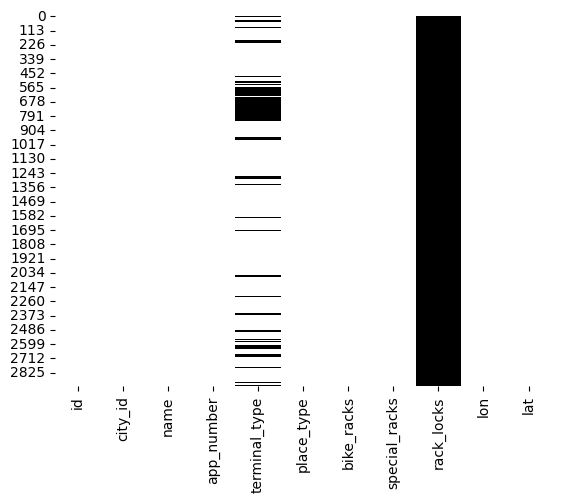

In [103]:
sns.heatmap(stations.isna(), cbar=False, cmap='binary')
plt.show()

In [104]:
stations = stations.drop(columns=['rack_locks'])
stations.columns

Index(['id', 'city_id', 'name', 'app_number', 'terminal_type', 'place_type',
       'bike_racks', 'special_racks', 'lon', 'lat'],
      dtype='object')

In [105]:
stations['terminal_type'].unique()  
stations['terminal_type'].nunique()   

array([nan, 'stele', 'smart_sign', 'sign', '7inch', 'free', 'character',
       'traffic_sign', 'mmt', 'terminal_sleek', 'pult'], dtype=object)

10

terminal_type
sign              881
7inch             386
stele             329
free              276
smart_sign        162
traffic_sign      156
character         113
mmt                25
pult               14
terminal_sleek      3
Name: count, dtype: int64

terminal_type
sign              37.569296
7inch             16.460554
stele             14.029851
free              11.769723
smart_sign         6.908316
traffic_sign       6.652452
character          4.818763
mmt                1.066098
pult               0.597015
terminal_sleek     0.127932
Name: proportion, dtype: float64

<Axes: title={'center': 'Station Count by Terminal Type'}, xlabel='Terminal Type', ylabel='Number of Stations'>

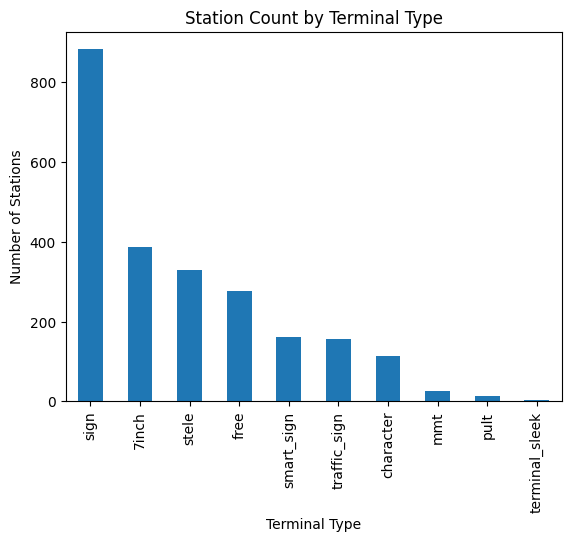

In [110]:
# 1. Get exact value counts as a table
stations['terminal_type'].value_counts()

# 2. Get percentage distribution across hardware types[cite: 5]
stations['terminal_type'].value_counts(normalize=True) * 100

# 3. Quick Pandas vertical bar chart
stations['terminal_type'].value_counts().plot(
    kind='bar',
    xlabel='Terminal Type',
    ylabel='Number of Stations',
    title='Station Count by Terminal Type'
)
plt.show()

In [111]:
stations_status.head(10)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False
5,137700,1.661531e+09,15,0,15,1,0,False
6,50464,1.661531e+09,3,0,3,3,0,False
7,6290772,1.661531e+09,3,0,3,1,0,False
8,8341045,1.661531e+09,10,0,10,0,0,False
9,3581060,1.661531e+09,7,0,7,8,6,False


In [112]:
stations_status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


In [113]:
missing_summary = stations_status.isna().agg(['sum', 'mean']).T.rename(columns={'sum': 'count', 'mean': 'pct'})
missing_summary['pct'] *= 100
missing_summary[missing_summary['count'] > 0].sort_values(by='pct', ascending=False)

,count,pct


In [116]:
# 1. Convert numeric UTC timestamp (seconds) to UTC datetime
stations_status['datetime'] = pd.to_datetime(stations_status['time'], unit='s', utc=True)

# 2. Extract separate numeric day and hour columns
stations_status['day_of_month'] = stations_status['datetime'].dt.day         # 1 to 31
stations_status['day_of_week']  = stations_status['datetime'].dt.day_name()   # e.g., 'Monday'
stations_status['hour']         = stations_status['datetime'].dt.hour       # 0 to 23

stations_status.head(10)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,day_of_month,day_of_week,hour
0,101896428,1.661530e+09,2,0,2,0,0,False,2022-08-26 16:14:01+00:00,26,Friday,16
1,54643,1.661531e+09,1,0,1,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
2,6201611,1.661531e+09,3,0,3,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
3,294346,1.661531e+09,8,0,8,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
4,781866,1.661531e+09,1,1,0,5,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
5,137700,1.661531e+09,15,0,15,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
6,50464,1.661531e+09,3,0,3,3,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
7,6290772,1.661531e+09,3,0,3,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
8,8341045,1.661531e+09,10,0,10,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
9,3581060,1.661531e+09,7,0,7,8,6,False,2022-08-26 16:15:01+00:00,26,Friday,16
